# ML practice

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
import os
from imblearn.over_sampling import RandomOverSampler

print(os.getcwd())

print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Pandas:", pd.__version__)

/Users/manishsingh/Downloads/python/magic+gamma+telescope
NumPy: 2.5.3
Matplotlib: 3.11.2
Pandas: 3.0.6


## Dataset:
###
Dataset:
Dua,D. and Graff, C. (2019). UCI Machine Learning Repository [http://archive.ics.uci.edu/m1]• Irvine, CA: University, of California, School of Information and Computer Science.
Donated by: P. Savicky
Institute of Computer Science, AS of CR
Czech Republic
savicky '@' cs.cas.cz

In [59]:
import pandas as pd

df = pd.read_csv("magic04.data", header=None)

df.columns = [
    "fLength", "fWidth", "fSize", "fConc", "fConc1",
    "fAsym", "fM3Long", "fM3Trans", "fAlpha", "fDist", "class"
]
df.head()


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [60]:
df["class"] = (df["class"] == "g").astype(int)

In [61]:
df["class"].value_counts()

class
1    12332
0     6688
Name: count, dtype: int64

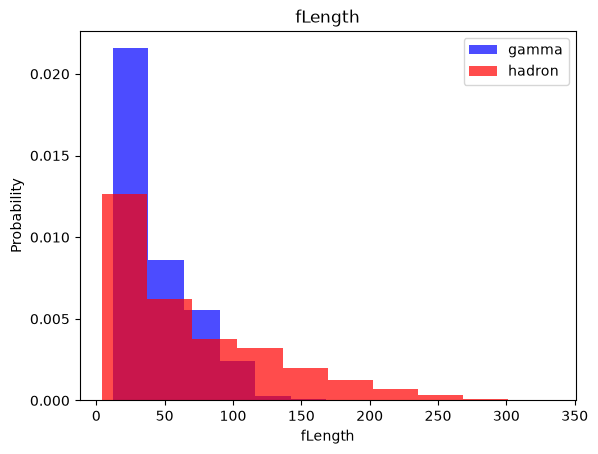

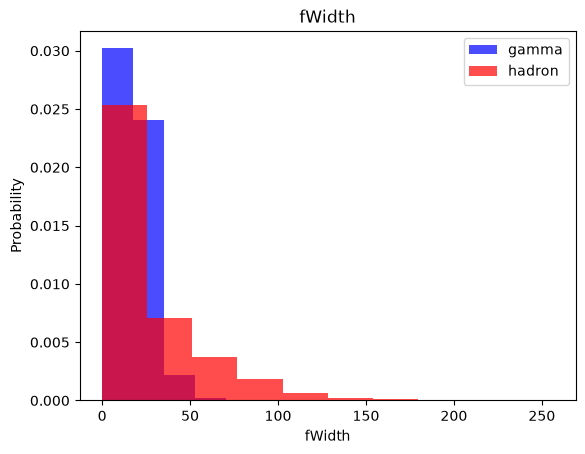

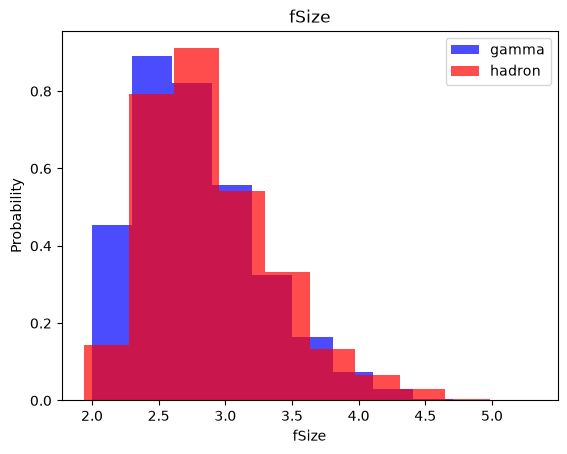

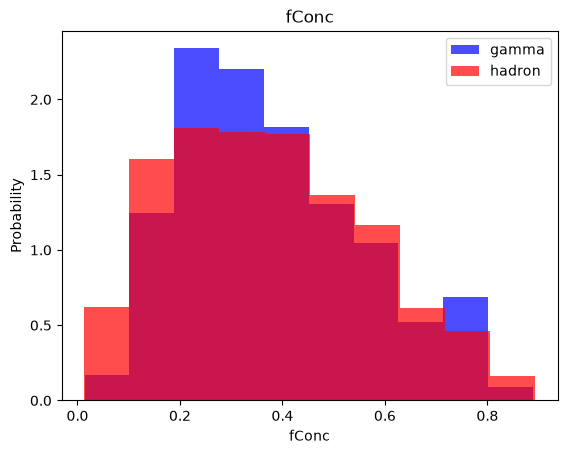

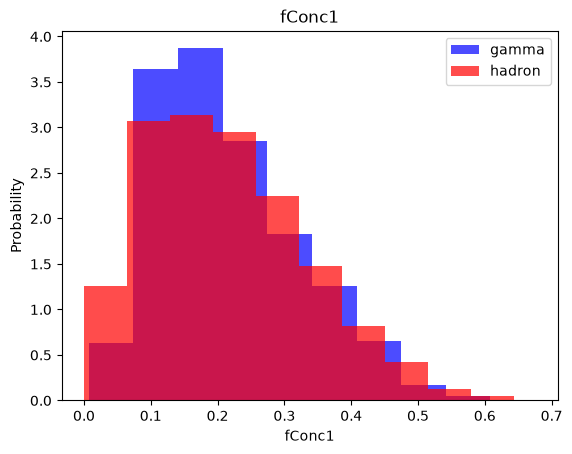

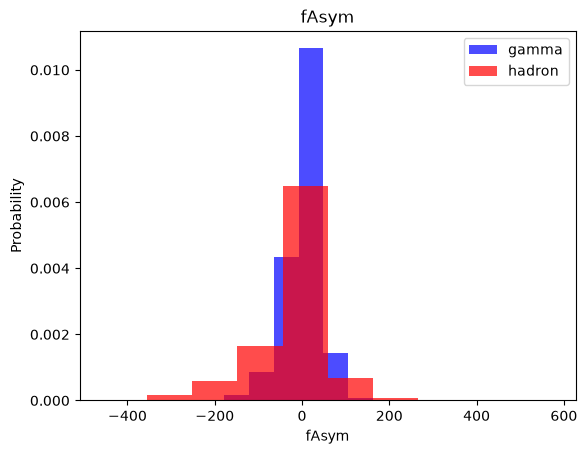

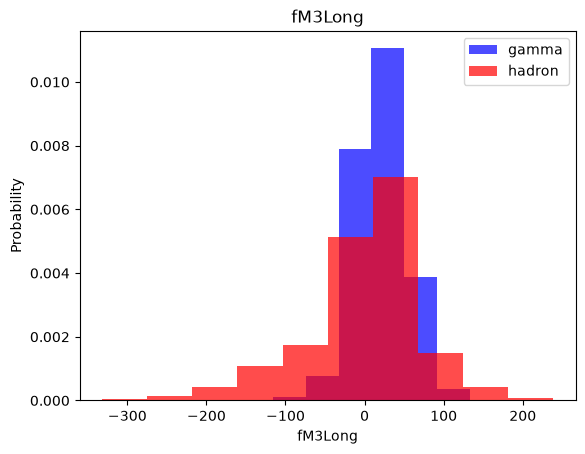

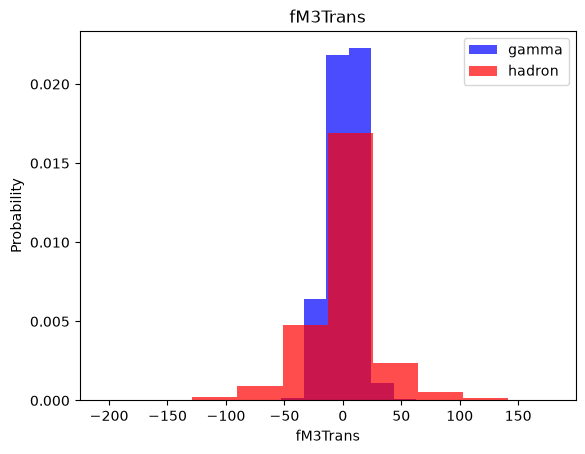

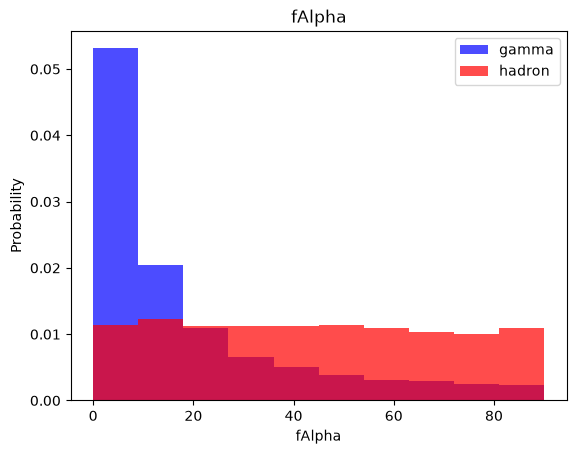

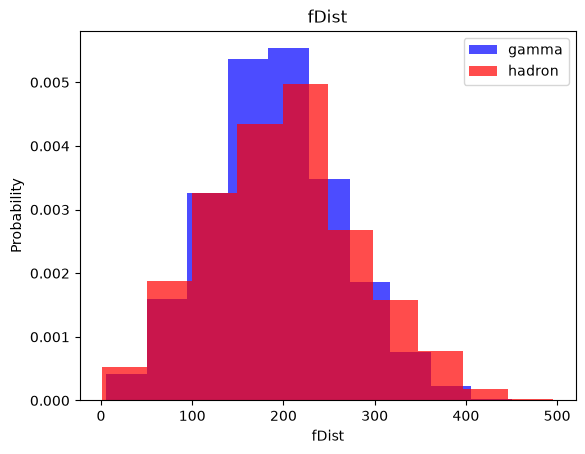

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("magic04.data", header=None)

cols = [
    "fLength", "fWidth", "fSize", "fConc", "fConc1",
    "fAsym", "fM3Long", "fM3Trans", "fAlpha", "fDist", "class"
]

df.columns = cols

df["class"] = (df["class"] == "g").astype(int)

for label in cols[:-1]:
    plt.hist(df[df["class"] == 1][label],
             color="blue", label="gamma",
             alpha=0.7, density=True)

    plt.hist(df[df["class"] == 0][label],
             color="red", label="hadron",
             alpha=0.7, density=True)

    plt.xlabel(label)
    plt.ylabel("Probability")
    plt.title(label)
    plt.legend()
    plt.show()

## Train , validation and test split

In [63]:
shuffled_df = df.sample(frac=1, random_state=42)
train_end = int(0.6 * len(shuffled_df))
valid_end = int(0.8 * len(shuffled_df))

train = shuffled_df.iloc[:train_end].copy()
valid = shuffled_df.iloc[train_end:valid_end].copy()
test = shuffled_df.iloc[valid_end:].copy()

In [64]:
def scale_dataset (dataframe ,oversample=False):
    x = dataframe[dataframe.columns[:-1]].values
    y = dataframe[dataframe.columns[-1]].values
    scaler = StandardScaler()
    x = scaler.fit_transform(x)
    
    if oversample:
        ros = RandomOverSampler()
        x, y = ros.fit_resample(x, y)
        
    data = np.hstack((x,np.reshape(y, (-1, 1))))
    return data, x, y

In [65]:
train_data, x_train, y_train = scale_dataset(train, oversample=True)

In [66]:
len(y_train)

14818

In [67]:
sum (y_train==1)

np.int64(7409)

In [68]:
sum (y_train==0)

np.int64(7409)

## KNN

In [69]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [70]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [71]:
_, x_test, y_test = scale_dataset(test)
y_pred = knn_model.predict(x_test)

In [72]:

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.72      0.73      0.72      1331
           1       0.85      0.84      0.85      2473

    accuracy                           0.80      3804
   macro avg       0.78      0.79      0.79      3804
weighted avg       0.80      0.80      0.80      3804



## Naive byes 

In [73]:
from sklearn.naive_bayes import GaussianNB

In [74]:
nb_model = GaussianNB()
nb_model = nb_model.fit(x_train, y_train)

In [75]:
y_pred = nb_model.predict(x_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.66      0.39      0.49      1331
           1       0.73      0.89      0.80      2473

    accuracy                           0.72      3804
   macro avg       0.69      0.64      0.65      3804
weighted avg       0.71      0.72      0.69      3804



## logistic regression


In [76]:
from sklearn.linear_model import LogisticRegression

In [77]:
lg_model = LogisticRegression()
lg_model = lg_model.fit(x_train, y_train)

In [78]:
y_pred = lg_model.predict(x_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.67      0.71      0.69      1331
           1       0.84      0.81      0.82      2473

    accuracy                           0.77      3804
   macro avg       0.75      0.76      0.76      3804
weighted avg       0.78      0.77      0.78      3804



## SVM




In [79]:
from sklearn.svm import SVC

In [80]:
svm_model = SVC()
svm_model = svm_model.fit(x_train, y_train)

In [81]:
y_pred = svm_model.predict(x_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.79      0.79      1331
           1       0.89      0.90      0.89      2473

    accuracy                           0.86      3804
   macro avg       0.84      0.84      0.84      3804
weighted avg       0.86      0.86      0.86      3804



# NEURAL NETWORK

In [82]:
import tensorflow as tf

In [83]:
def plot_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6)) # Added figsize for better viewing
    
    # Plot Loss
    ax1.plot(history.history['loss'], label='loss')
    ax1.plot(history.history['val_loss'], label='val_loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Binary crossentropy')
    ax1.grid(True)
    ax1.legend() # Good practice to add this

    # Plot Accuracy
    ax2.plot(history.history['accuracy'], label='accuracy')
    ax2.plot(history.history['val_accuracy'], label='val_accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.grid(True)
    ax2.legend() # Good practice to add this

    plt.show()

In [84]:
import tensorflow as tf
import numpy as np
import random

seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)
random.seed(seed)

In [85]:
nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(10,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.2), # <-- Add this
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.2), # <-- Add this
    tf.keras.layers.Dense(1, activation='sigmoid')
])

nn_model.compile(optimizer=tf.keras.optimizers.Adam(0.001) , loss= 'binary_crossentropy',
                 metrics = ['accuracy'])

In [86]:
def train_model(x_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs):
    nn_model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(10,)),
        tf.keras.layers.Dense(num_nodes, activation='relu'),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation='relu'),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    
    nn_model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='binary_crossentropy',
                     metrics=['accuracy'])
    
    history = nn_model.fit(
        x_train, y_train,  # These are now the parameters passed in
        epochs=epochs, 
        batch_size=batch_size, 
        validation_split=0.2, 
        verbose=0
    )
    return nn_model, history



In [87]:
# 2. Setup a smaller grid search to test locally
epochs = 100 
best_val_accuracy = 0
best_params = {}

for num_nodes in [16, 32]: # Reduced to 2 options
    for dropout_prob in [0, 0.2]:
        for lr in [0.01, 0.005]: # Reduced to 2 options
            for batch_size in [32, 64]:
                print(f"Training with: nodes={num_nodes}, dropout={dropout_prob}, lr={lr}, batch_size={batch_size}")
                
                # FIXED: Added x_train and y_train here
                model, history = train_model(x_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs)
                
                # Keep track of the best model instead of plotting 32 times
                val_acc = max(history.history['val_accuracy'])
                if val_acc > best_val_accuracy:
                    best_val_accuracy = val_acc
                    best_params = {'num_nodes': num_nodes, 'dropout_prob': dropout_prob, 'lr': lr, 'batch_size': batch_size}

print("\n--- Tuning Complete ---")
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")
print(f"Best Parameters: {best_params}")

Training with: nodes=16, dropout=0, lr=0.01, batch_size=32
Training with: nodes=16, dropout=0, lr=0.01, batch_size=64
Training with: nodes=16, dropout=0, lr=0.005, batch_size=32
Training with: nodes=16, dropout=0, lr=0.005, batch_size=64
Training with: nodes=16, dropout=0.2, lr=0.01, batch_size=32
Training with: nodes=16, dropout=0.2, lr=0.01, batch_size=64
Training with: nodes=16, dropout=0.2, lr=0.005, batch_size=32
Training with: nodes=16, dropout=0.2, lr=0.005, batch_size=64
Training with: nodes=32, dropout=0, lr=0.01, batch_size=32
Training with: nodes=32, dropout=0, lr=0.01, batch_size=64
Training with: nodes=32, dropout=0, lr=0.005, batch_size=32
Training with: nodes=32, dropout=0, lr=0.005, batch_size=64
Training with: nodes=32, dropout=0.2, lr=0.01, batch_size=32
Training with: nodes=32, dropout=0.2, lr=0.01, batch_size=64
Training with: nodes=32, dropout=0.2, lr=0.005, batch_size=32
Training with: nodes=32, dropout=0.2, lr=0.005, batch_size=64

--- Tuning Complete ---
Best Va

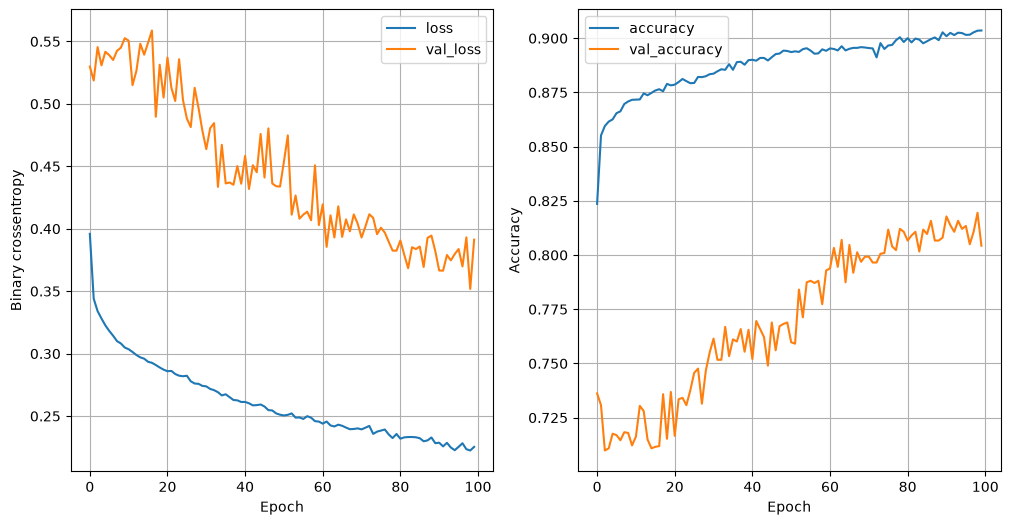

In [90]:
# 1. Create the model using the best parameters found
nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(10,)),
    tf.keras.layers.Dense(32, activation='relu'), # Best num_nodes
    tf.keras.layers.Dropout(0),                   # Best dropout_prob
    tf.keras.layers.Dense(32, activation='relu'), 
    tf.keras.layers.Dropout(0),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# 2. Compile using the best learning rate
nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(0.01),     # Best lr
    loss='binary_crossentropy', 
    metrics=['accuracy']
)

# 3. Train using the best batch size
history = nn_model.fit(
    x_train, y_train, 
    epochs=100, 
    batch_size=64,                                # Best batch_size
    validation_split=0.2, 
    verbose=0
)

plot_history(history)

In [91]:
y_pred = nn_model.predict(x_test)
y_pred = (y_pred > 0.5).astype(int).reshape(-1,)

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 272us/step


In [92]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.74      0.78      1331
           1       0.87      0.91      0.89      2473

    accuracy                           0.85      3804
   macro avg       0.85      0.83      0.84      3804
weighted avg       0.85      0.85      0.85      3804

